<center><h1>Liang_Qian_HW5</h1></center>
<br>
<br>

Name: Qian Liang
<br>
Github Username: qliang21-77
<br>
USC ID:  9681620075

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import numpy as np
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.utils.validation import check_is_fitted
from sklearn.tree import _tree
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
import seaborn as sns
import matplotlib.pyplot as plt

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pains",
    "Burning_Urethra",
    "Bladder_Inflammation",
    "Nephritis"
]

df = pd.read_csv(
    "diagnosis.data",
    sep="\t",
    header=None,
    names=columns,
    decimal=",",
    encoding="utf-16"
)

df.head()

,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Bladder_Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

In [3]:

binary_cols = df.columns[1:]

for col in binary_cols:
    df[col] = df[col].map({'yes': 1, 'no': 0})

df.head()

,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Bladder_Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [4]:

# Prepare x and y 

X = df.iloc[:, :6].copy()
y = df.iloc[:, 6:].copy()

# Convert yes/no to 1/0
for col in X.columns[1:]:
    X[col] = X[col].replace({"yes": 1, "no": 0})

for col in y.columns:
    y[col] = y[col].replace({"yes": 1, "no": 0})

# Ensure numeric data
X = X.apply(pd.to_numeric)
y = y.apply(pd.to_numeric)

# Check missing values
print("X missing values:", X.isna().sum().sum())
print("y missing values:", y.isna().sum().sum())

# Create and fit model
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y);


X missing values: 0
y missing values: 0


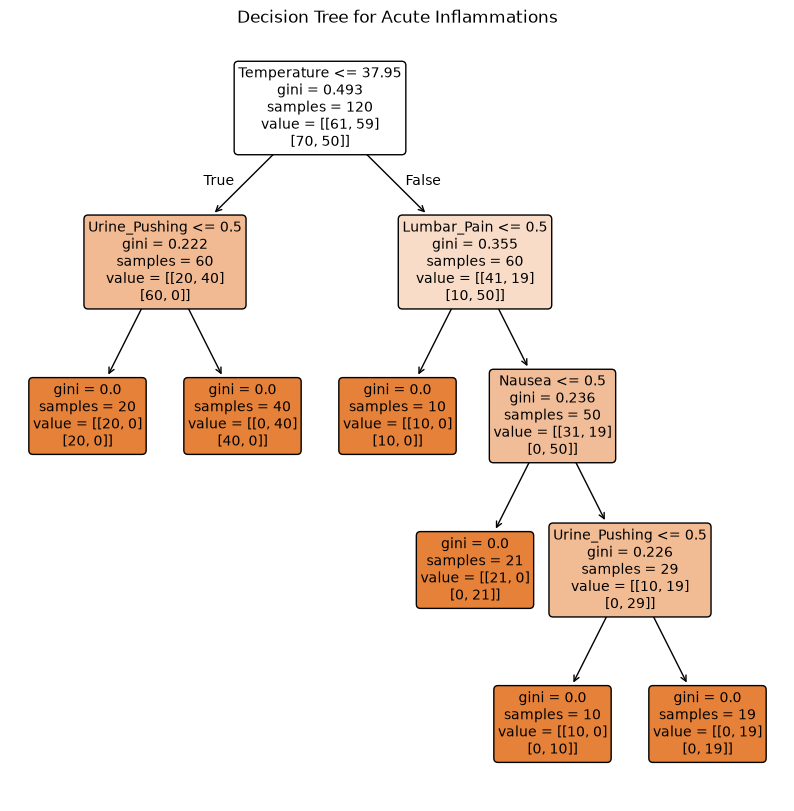

In [5]:
plt.figure(figsize=(10, 10))

tree.plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Acute Inflammations")
plt.show()


### (c) Convert the decision rules

In [6]:
def tree_to_rules(model, feature_names, outcome_names):
    tree_ = model.tree_
    feature_names = list(feature_names)
    outcome_names = list(outcome_names)

    def recurse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree_.feature[node]]
            threshold = tree_.threshold[node]

            recurse(
                tree_.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )

            recurse(
                tree_.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )
        else:
            print("IF " + " AND ".join(conditions))

            for i, outcome in enumerate(outcome_names):
                class_index = np.argmax(tree_.value[node][i])
                predicted = model.classes_[i][class_index]
                print(f"RETURN {outcome} = {predicted}")

            print("-" * 50)

    recurse(0, [])

tree_to_rules(model, X.columns, y.columns)

IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 0
--------------------------------------------------
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
RETURN Bladder_Inflammation = 1
RETURN Nephritis = 0
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 0
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 1
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 1
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50
RETURN Bladder_Inflammation = 1
RETURN Nephritis = 1
-------------------------------------

### (d) cost-complexity pruning

In [7]:
pruning = model.cost_complexity_pruning_path(X, y)
alpha = pruning.ccp_alphas

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"ccp_alpha": alpha[:-1]},
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X, y)

print(grid_search.best_params_)
print(grid_search.best_score_)
alpha_search = pd.DataFrame({
    "Alpha": grid_search.cv_results_["param_ccp_alpha"],
    "Accuracy": grid_search.cv_results_["mean_test_score"]
})

print(alpha_search)

{'ccp_alpha': np.float64(0.0)}
0.95
      Alpha  Accuracy
0  0.000000  0.950000
1  0.049083  0.741667
2  0.079472  0.708333
3  0.111111  0.566667


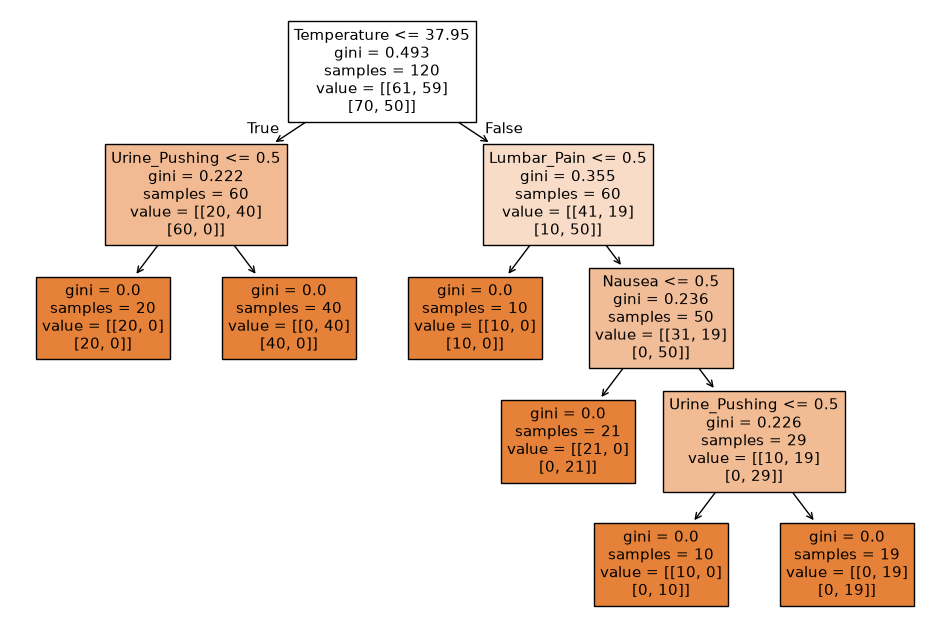

In [8]:
pruned_tree = grid_search.best_estimator_

plt.figure(figsize=(12, 8))
tree.plot_tree(pruned_tree, feature_names=X.columns, filled=True)
plt.show()

In [9]:
tree_to_rules(pruned_tree, X.columns, y.columns)

IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 0
--------------------------------------------------
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
RETURN Bladder_Inflammation = 1
RETURN Nephritis = 0
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 0
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 1
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50
RETURN Bladder_Inflammation = 0
RETURN Nephritis = 1
--------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50
RETURN Bladder_Inflammation = 1
RETURN Nephritis = 1
-------------------------------------

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
df2 = pd.read_csv(
    "communities.data",
    header=None,
    na_values="?"
)

train = df2.iloc[:1495]
test = df2.iloc[1495:]

print("Training set:", train.shape)
print("Test set:", test.shape)

Training set: (1495, 128)
Test set: (499, 128)


### (b) Missing values

In [11]:
df2.drop([0, 1, 2, 3, 4], axis=1, inplace=True)

train = df2.iloc[:1495]
test = df2.iloc[1495:]

X_train = train.drop(columns=[127])
X_test = test.drop(columns=[127])

y_train = train[127]
y_test = test[127]

imputer = SimpleImputer(strategy="mean")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

### (c) Plot a correlation matrix

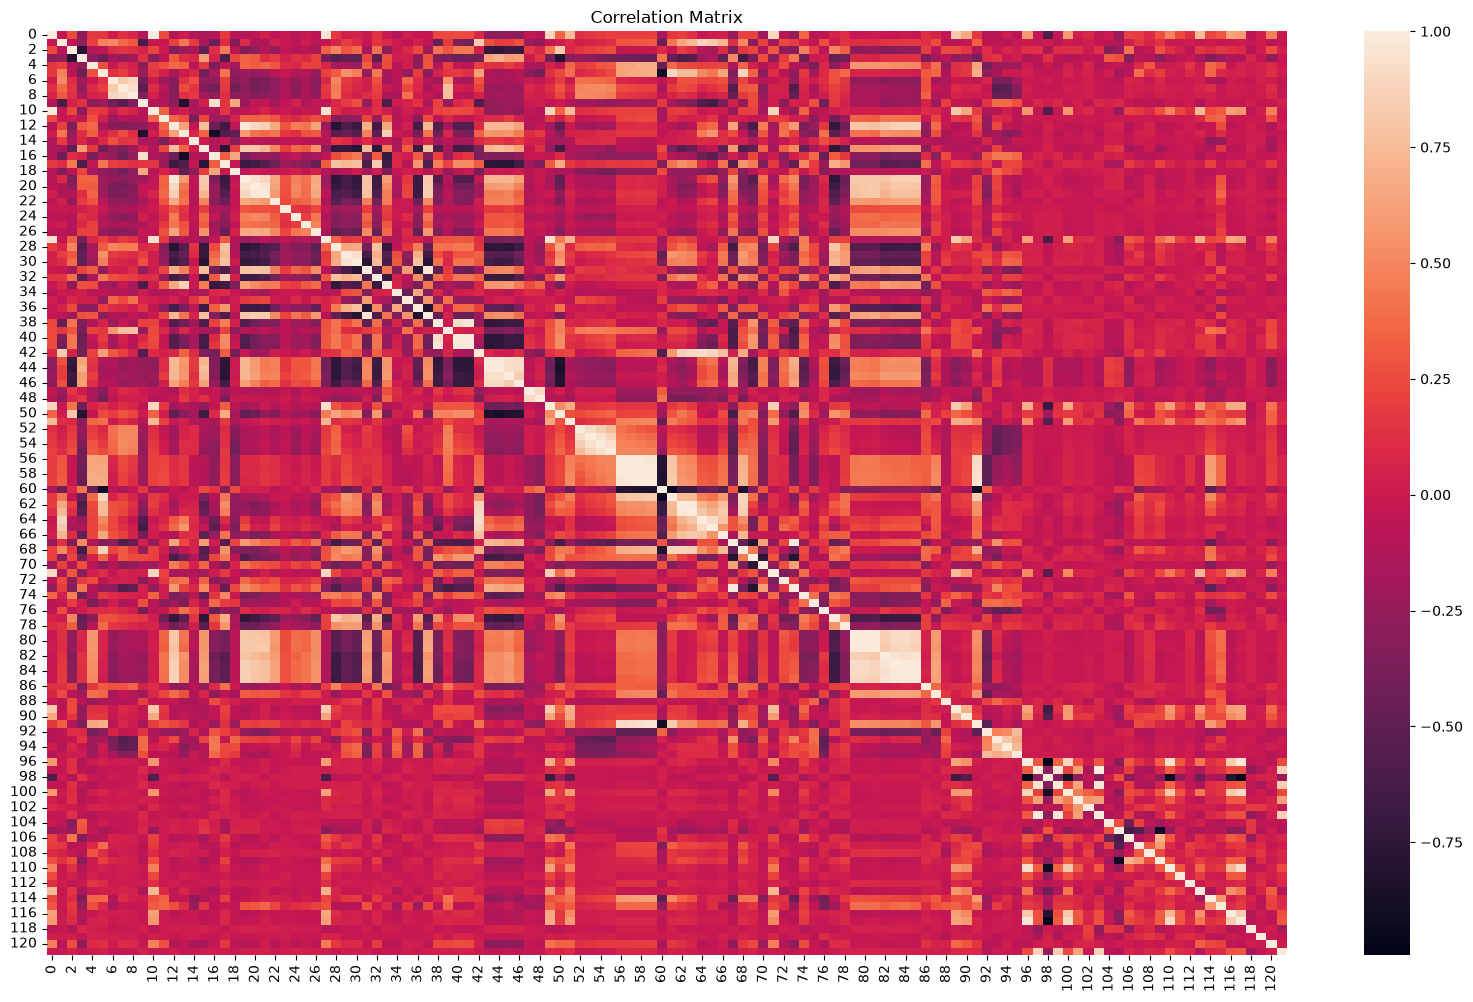

In [12]:
corr = pd.DataFrame(X_train).corr()

plt.figure(figsize=(20,12))
sns.heatmap(corr)
plt.title("Correlation Matrix")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [13]:
cv = pd.DataFrame(X_train).std() / pd.DataFrame(X_train).mean()

print(cv)

0      2.241105
1      0.355800
2      1.428885
3      0.330213
4      1.359100
         ...   
117    0.743487
118    0.115739
119    0.362989
120    2.552946
121    0.326026
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

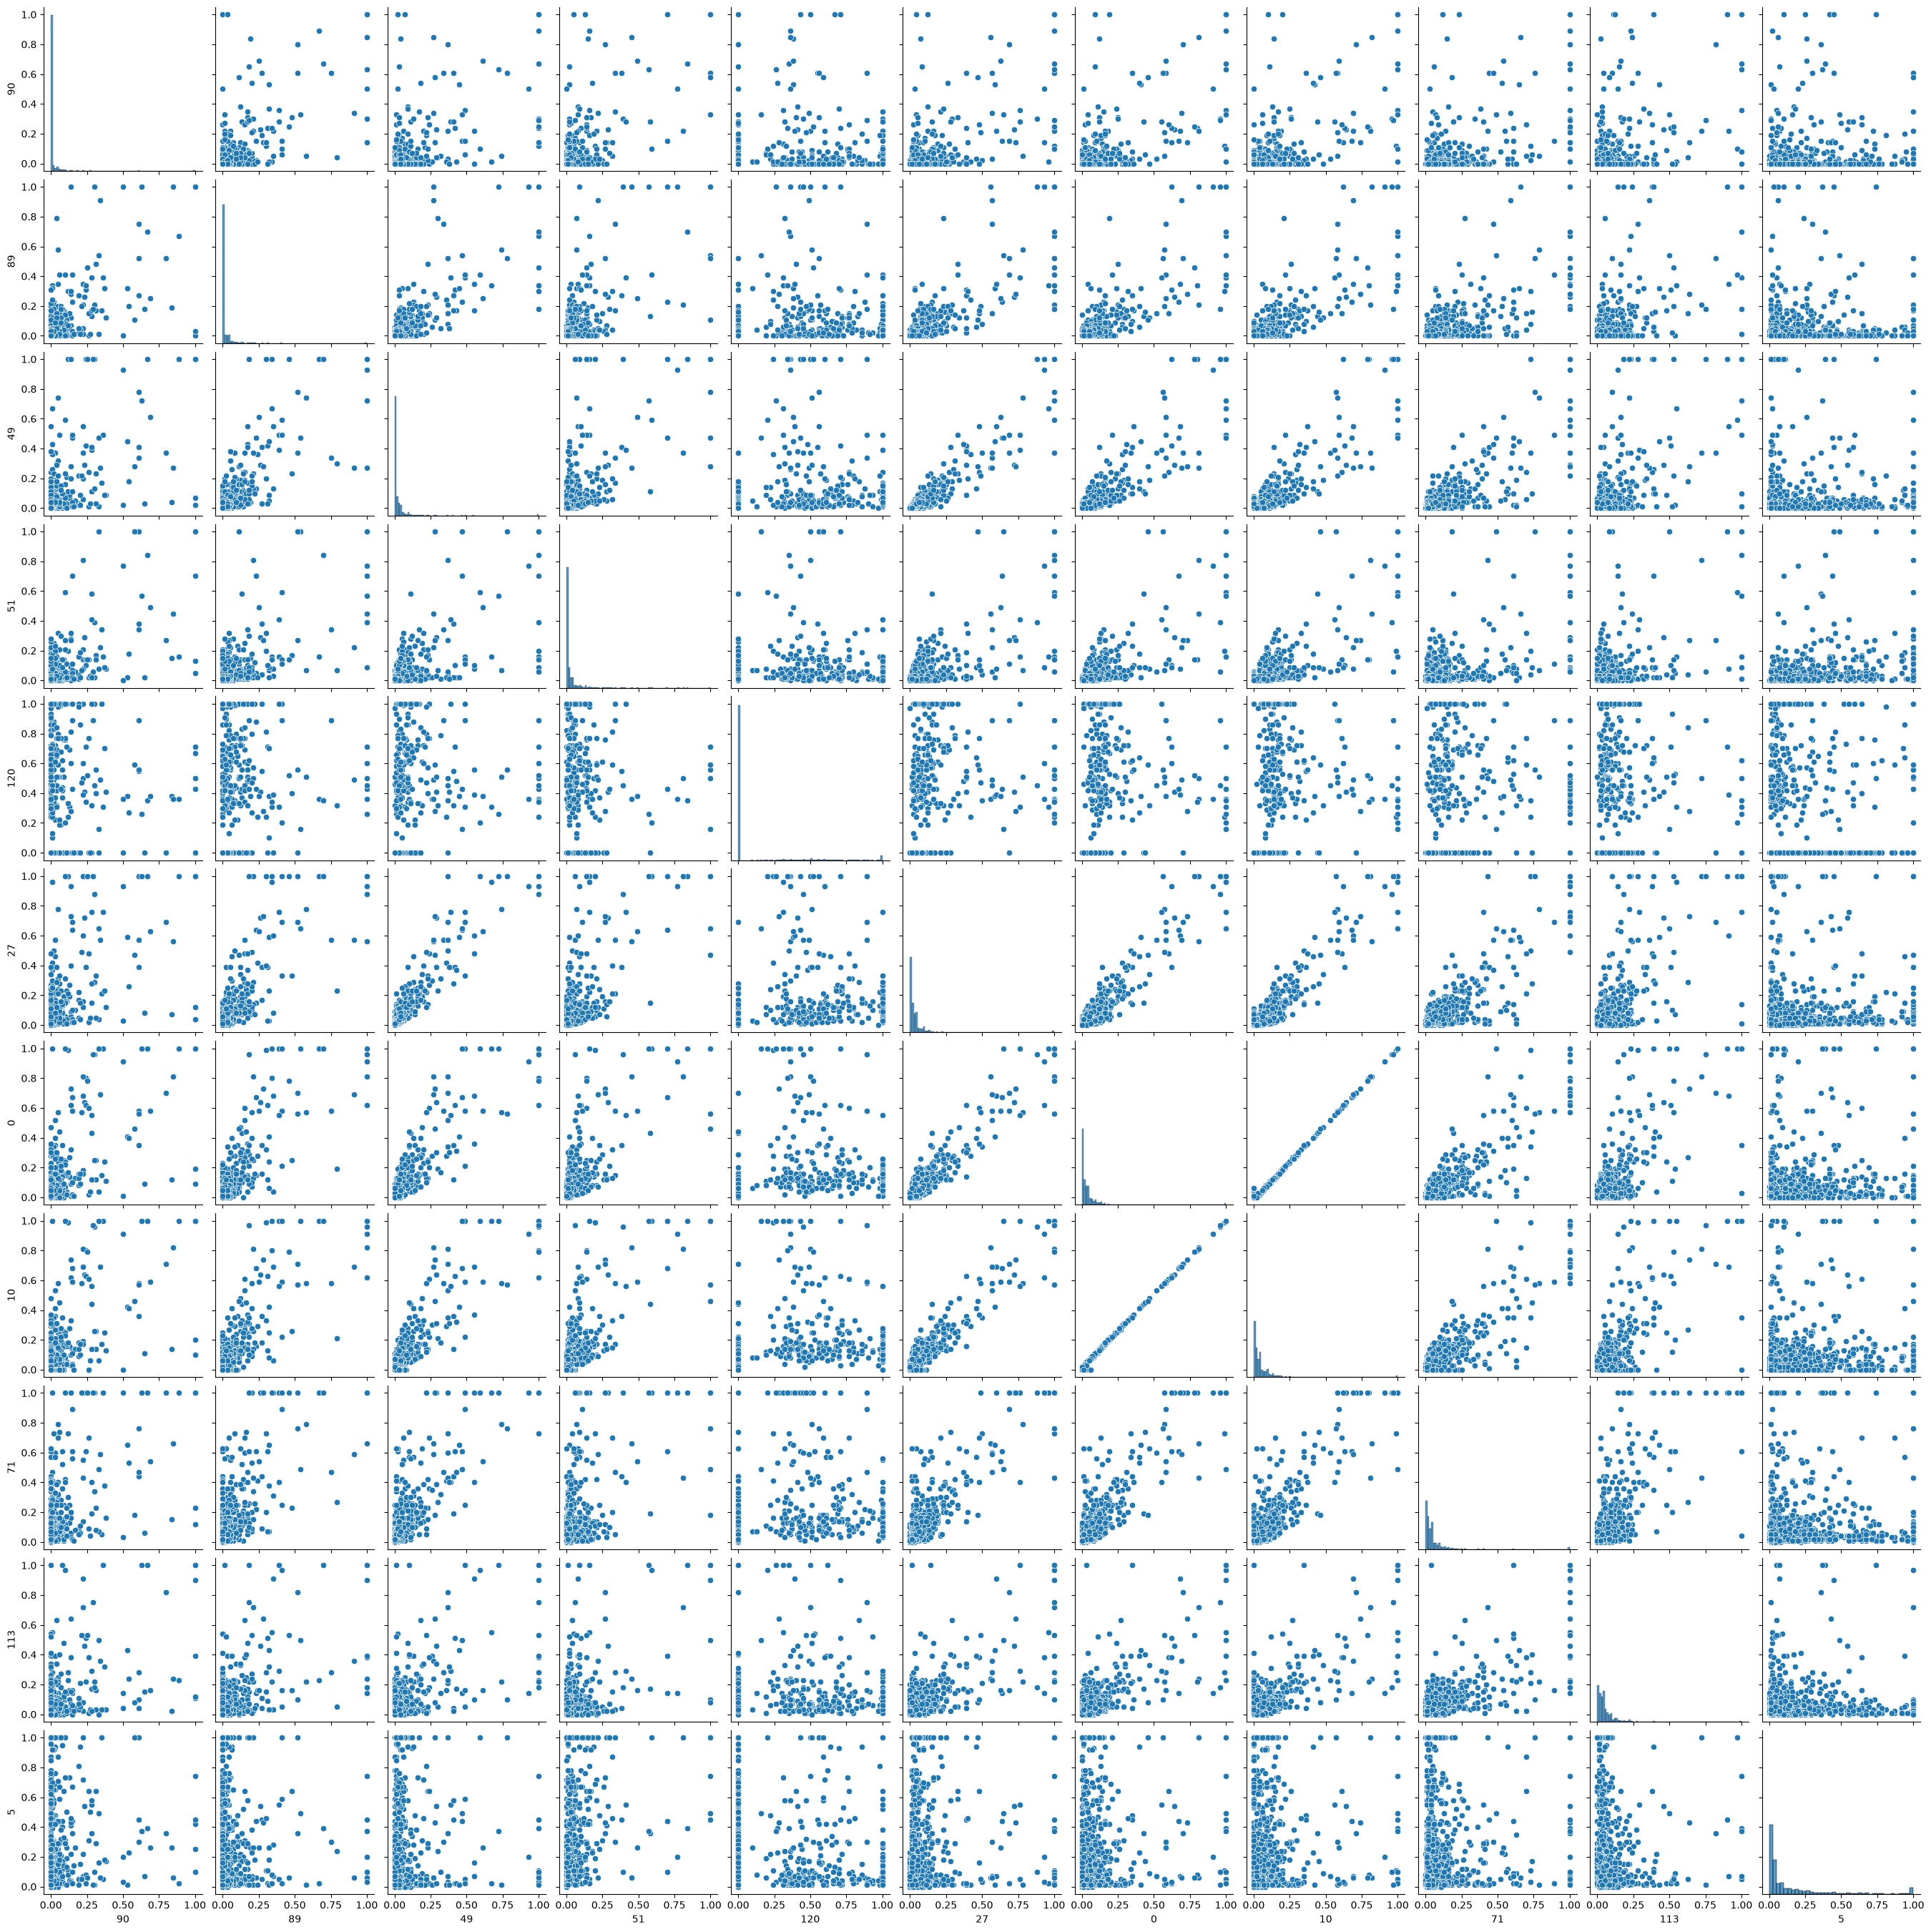

In [14]:
cv_sorted = cv.sort_values(ascending=False)
top_11 = cv_sorted.head(11)
selected_features = pd.DataFrame(X_train).iloc[:, top_11.index]
sns.pairplot(selected_features)
plt.show()

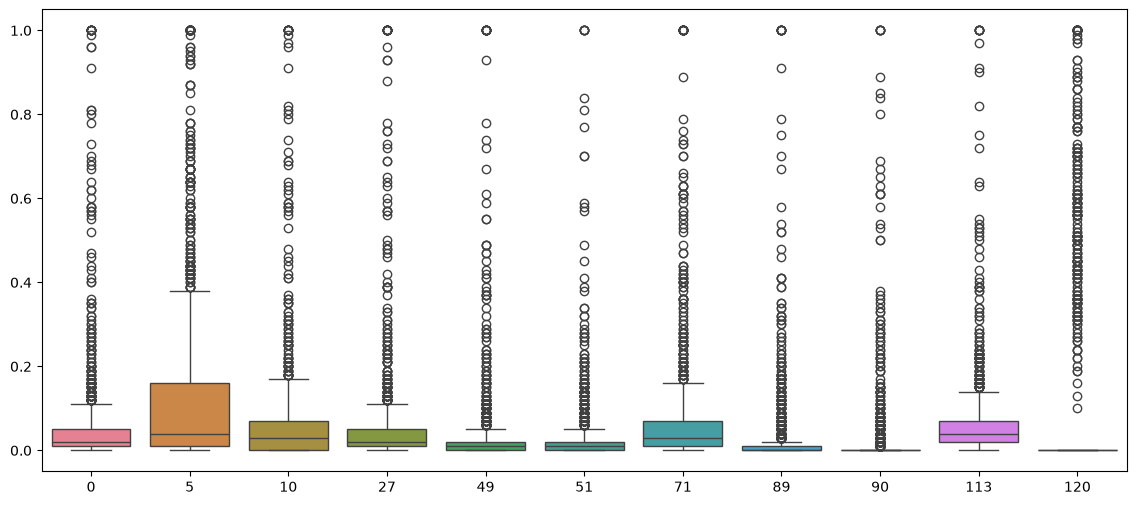

In [15]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=selected_features)
plt.show()

### (f) Fit a linear model

In [16]:
from sklearn.linear_model import LinearRegression
linear_reg = LinearRegression().fit(X_train, y_train)
from sklearn.metrics import mean_squared_error

y_pred = linear_reg.predict(X_test)

test_mse = mean_squared_error(y_test, y_pred)

print("Test MSE:", test_mse)

Test MSE: 0.01814197113553011


### (g) Fit a ridge regression model

In [17]:
from sklearn.linear_model import RidgeCV
lambdas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

ridge = RidgeCV(alphas=lambdas, cv=5)
ridge.fit(X_train, y_train)

print("Best lambdas:", ridge.alpha_)
print("Test MSE:", mean_squared_error(y_test, ridge.predict(X_test)))

Best lambdas: 1.0
Test MSE: 0.01773247499289662


### (h) Fit a LASSO model

In [18]:
from sklearn.linear_model import LassoCV
lasso = LassoCV(cv=5, random_state=42, max_iter=100000).fit(X_train, y_train)

print("Best Lambda:", lasso.alpha_)
print("Test MSE:", mean_squared_error(y_test, lasso.predict(X_test)))
print("Selected Features:", np.where(lasso.coef_ != 0)[0] + 5)

Best Lambda: 0.00011614723626829858
Test MSE: 0.017758209216319678
Selected Features: [  7   9  11  12  16  18  19  20  21  22  23  26  27  28  29  30  31  33
  34  38  39  41  43  44  45  49  50  51  53  54  55  56  60  64  66  68
  69  72  73  74  75  76  77  79  80  81  82  83  84  87  90  91  92  93
  94  95  96  97  99 104 105 107 109 111 113 115 116 117 118 119 120 123
 124 125 126]


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso_scaled = LassoCV(cv=5, random_state=42, max_iter=100000).fit(X_train_scaled, y_train)

print("Best Lambda:", lasso_scaled.alpha_)
print("Test MSE:", mean_squared_error(y_test, lasso_scaled.predict(X_test_scaled)))
print("Selected Features:", np.where(lasso_scaled.coef_ != 0)[0] + 5)

Best Lambda: 0.0007630833878262516
Test MSE: 0.017805339276862273
Selected Features: [  7   9  11  12  16  18  19  20  21  22  23  26  27  28  29  30  31  33
  34  38  39  43  44  45  49  50  51  53  54  55  56  58  60  64  66  68
  69  72  73  74  76  77  79  80  81  82  83  87  90  91  92  93  94  95
  96  99 104 105 107 109 110 111 112 113 115 116 117 118 119 120 121 123
 124]


### (i) Fit a PCR model

In [20]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pcr = Pipeline([
    ('pca', PCA()),
    ('regression', LinearRegression())
])

param_grid = {'pca__n_components': range(1, X_train.shape[1] + 1)}

grid = GridSearchCV(pcr, param_grid, cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train_scaled, y_train)

print("Best Number of Components:", grid.best_params_['pca__n_components'])

Best Number of Components: 95


In [21]:
pcr_pred = grid.predict(X_test_scaled)

pcr_mse = mean_squared_error(y_test, pcr_pred)

print("PCR Test MSE:", pcr_mse)

PCR Test MSE: 0.018392931230387783


### (j) Fit a boosting tree

In [22]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [23]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score, KFold

alphas = range(0, 11)
scores_list = []

for alpha in alphas:
    xgb = XGBRegressor(reg_alpha=alpha, random_state=50)

    scores = cross_val_score(
        xgb, X_train, y_train,
        cv=KFold(n_splits=5, shuffle=True, random_state=50),
        scoring='neg_mean_squared_error'
    )

    scores_list.append(-scores.mean())

best_alpha = alphas[np.argmin(scores_list)]

print("Best Alpha:", best_alpha)

Best Alpha: 2


In [24]:
xgb = XGBRegressor(reg_alpha=best_alpha, random_state=50)
xgb.fit(X_train, y_train)

xgb_mse = mean_squared_error(y_test, xgb.predict(X_test))

print("Test MSE:", xgb_mse)

Test MSE: 0.01861293333755263


* References:
* https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html